# Pandas - Topic 10 - Time Series data¶


## Topic Objectives

- Understand and handle Time Series Data


## Import Package for Learning

In [233]:
import numpy as np
import pandas as pd

## Time Series data¶


In this notebook we will cover

- how to use Pandas capabilities to extract information from date/time
- how to resample your time series using .resample()
- how to calculate moving average using .rolling().mean()
- how to shift and calculate differences and percentual changes with .shift(), .diff() and .pct_change()

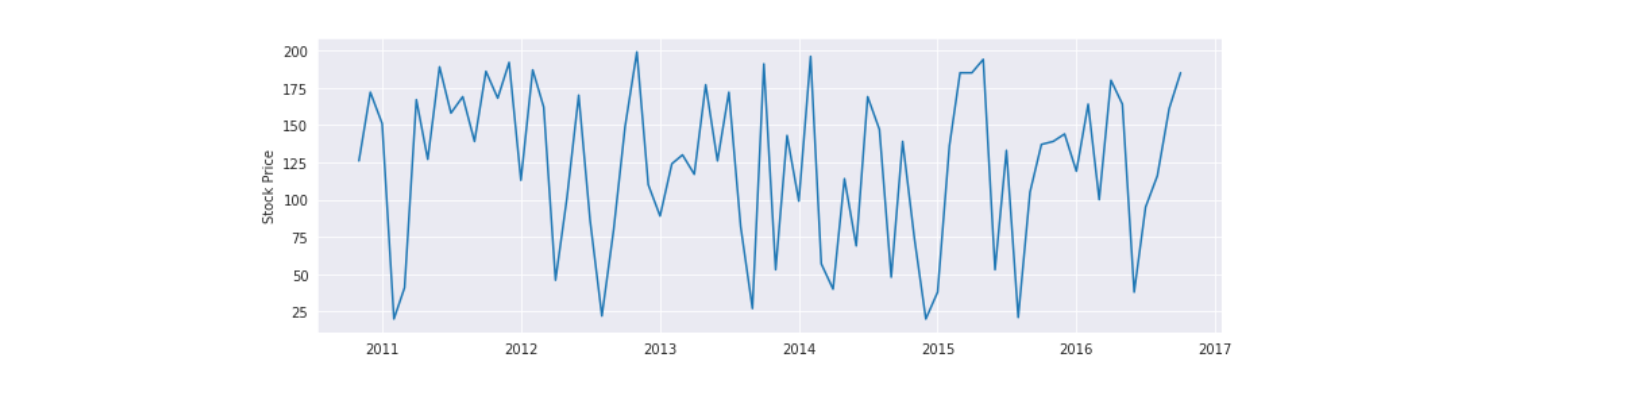

Pandas is also known for handling time series data.

The example below has a datetime index, hourly based, 24 periods starting from 27 Oct 2019

In [234]:
np.random.seed(3)
df = pd.DataFrame(data={'Col1':np.random.randint(low=20,high=35,size=24) }, 
                    index=pd.date_range(start='27/10/2019 00:00:00', periods=24,freq='H'))

df

C:\Users\zainab\AppData\Local\Temp\ipykernel_14380\1949799499.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  index=pd.date_range(start='27/10/2019 00:00:00', periods=24,freq='H'))


,Col1
2019-10-27 00:00:00,30
2019-10-27 01:00:00,28
2019-10-27 02:00:00,29
2019-10-27 03:00:00,23
2019-10-27 04:00:00,28
2019-10-27 05:00:00,28
2019-10-27 06:00:00,20
2019-10-27 07:00:00,25
2019-10-27 08:00:00,33
2019-10-27 09:00:00,23


### Extract information from date/time¶

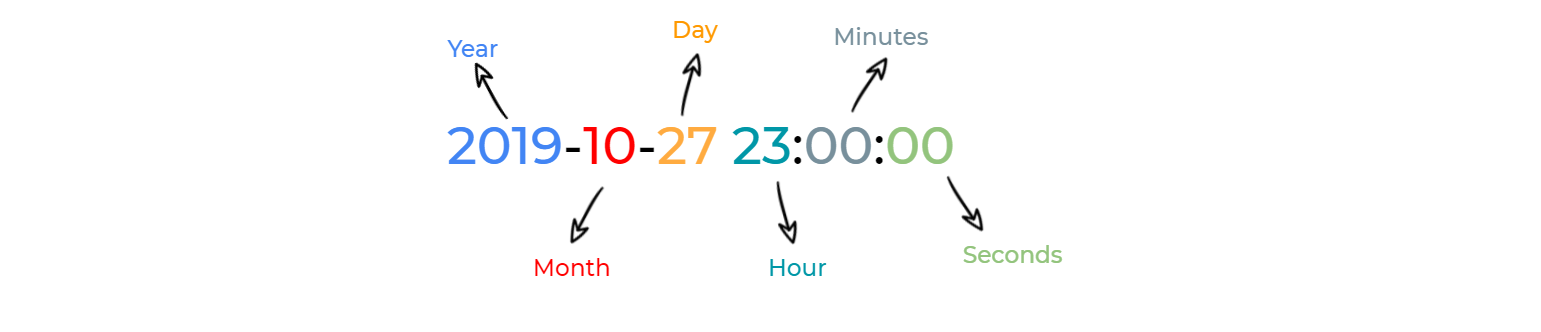

You can extract date information from your datetime index, accessing its attributes.

In [235]:
df['Hour'] = df.index.hour
df['Minute'] = df.index.minute
df['Seconds'] = df.index.second
df['Day'] = df.index.day
df['WeekDay_number'] = df.index.weekday
df['WeekDay_text'] = df.index.day_name()
df['Month_number'] = df.index.month
df['Month_short'] = df.index.month_name()
df['Year'] = df.index.year
df['Year-Month'] = df.index.to_period('M')

df.head()

,Col1,Hour,Minute,Seconds,Day,WeekDay_number,WeekDay_text,Month_number,Month_short,Year,Year-Month
2019-10-27 00:00:00,30,0,0,0,27,6,Sunday,10,October,2019,2019-10
2019-10-27 01:00:00,28,1,0,0,27,6,Sunday,10,October,2019,2019-10
2019-10-27 02:00:00,29,2,0,0,27,6,Sunday,10,October,2019,2019-10
2019-10-27 03:00:00,23,3,0,0,27,6,Sunday,10,October,2019,2019-10
2019-10-27 04:00:00,28,4,0,0,27,6,Sunday,10,October,2019,2019-10


You can start typing your DataFrame name, then .index.

- The image below shows a list containing all possible attributes (blue icon) and functions (purple icon). Each of these contains more methods for extracting datetime information, like .microsecond, .is_month_startor .month_name()

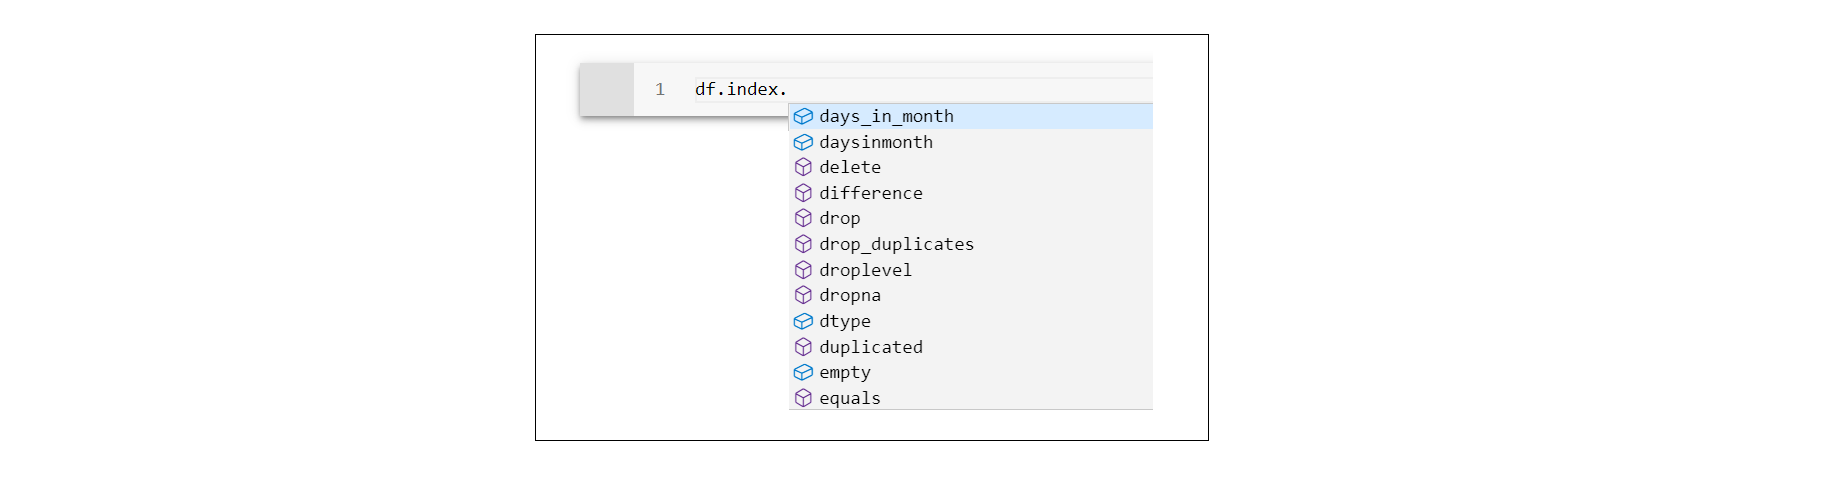

If your date variable is not in the index but is a column instead, you should add .dt to extract date information

Consider the same DataFrame, but instead of having datetime data as the index, but as a DataFrame column

In [236]:
df_date = pd.DataFrame(data={'Date':pd.date_range(start='27/10/2019 00:00:00', periods=24,freq='H'),
                             'Col1':np.random.randint(low=20,high=35,size=24)})

df_date.head()

C:\Users\zainab\AppData\Local\Temp\ipykernel_14380\3120608757.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_date = pd.DataFrame(data={'Date':pd.date_range(start='27/10/2019 00:00:00', periods=24,freq='H'),


,Date,Col1
0,2019-10-27 00:00:00,28
1,2019-10-27 01:00:00,30
2,2019-10-27 02:00:00,21
3,2019-10-27 03:00:00,30
4,2019-10-27 04:00:00,26


You should add .dt before the date information when indicating the datetime data is a column, not an index.

- We placed fewer examples here just to demonstrate the use case. You can use all the methods shown in the previous example

In [237]:
df_date['Hour'] = df_date['Date'].dt.hour
df_date['Minute'] = df_date['Date'].dt.minute
df_date['Year'] = df_date['Date'].dt.year
df_date.head()

,Date,Col1,Hour,Minute,Year
0,2019-10-27 00:00:00,28,0,0,2019
1,2019-10-27 01:00:00,30,1,0,2019
2,2019-10-27 02:00:00,21,2,0,2019
3,2019-10-27 03:00:00,30,3,0,2019
4,2019-10-27 04:00:00,26,4,0,2019


**PRACTICE:** The DataFrame below has a datetime index

In the cell indicated below

- add a column to the DataFrame named Weekday that shows the name of the day of the week.

In [238]:
np.random.seed(3)
df_index = pd.DataFrame(data={'Revenue':np.random.randint(low=20,high=35,size=28) }, 
                    index=pd.date_range(start='01/05/2021', periods=28,freq='D')
                    )
df_index.head()

,Revenue
2021-01-05,30
2021-01-06,28
2021-01-07,29
2021-01-08,23
2021-01-09,28


In [239]:
# Write your code here
df_index["weekday"] = df_index.index.weekday 

df_index.head()

,Revenue,weekday
2021-01-05,30,1
2021-01-06,28,2
2021-01-07,29,3
2021-01-08,23,4
2021-01-09,28,5


**PRACTICE:** The DataFrame below does not have a datetime index.

In the cell indicated below,

- add a column to the DataFrame named Month that shows the month name.

In [240]:
np.random.seed(3)
df_column = pd.DataFrame(data={'Date': pd.date_range(start='01/29/2021', periods=28,freq='D'),
                               'Revenue':np.random.randint(low=20,high=35,size=28)})
df_column.head()

,Date,Revenue
0,2021-01-29,30
1,2021-01-30,28
2,2021-01-31,29
3,2021-02-01,23
4,2021-02-02,28


In [241]:
# Write your code here
df_column["Month"] = df_column["Date"].dt.month 

df_column.head() 

,Date,Revenue,Month
0,2021-01-29,30,1
1,2021-01-30,28,1
2,2021-01-31,29,1
3,2021-02-01,23,2
4,2021-02-02,28,2


Resample

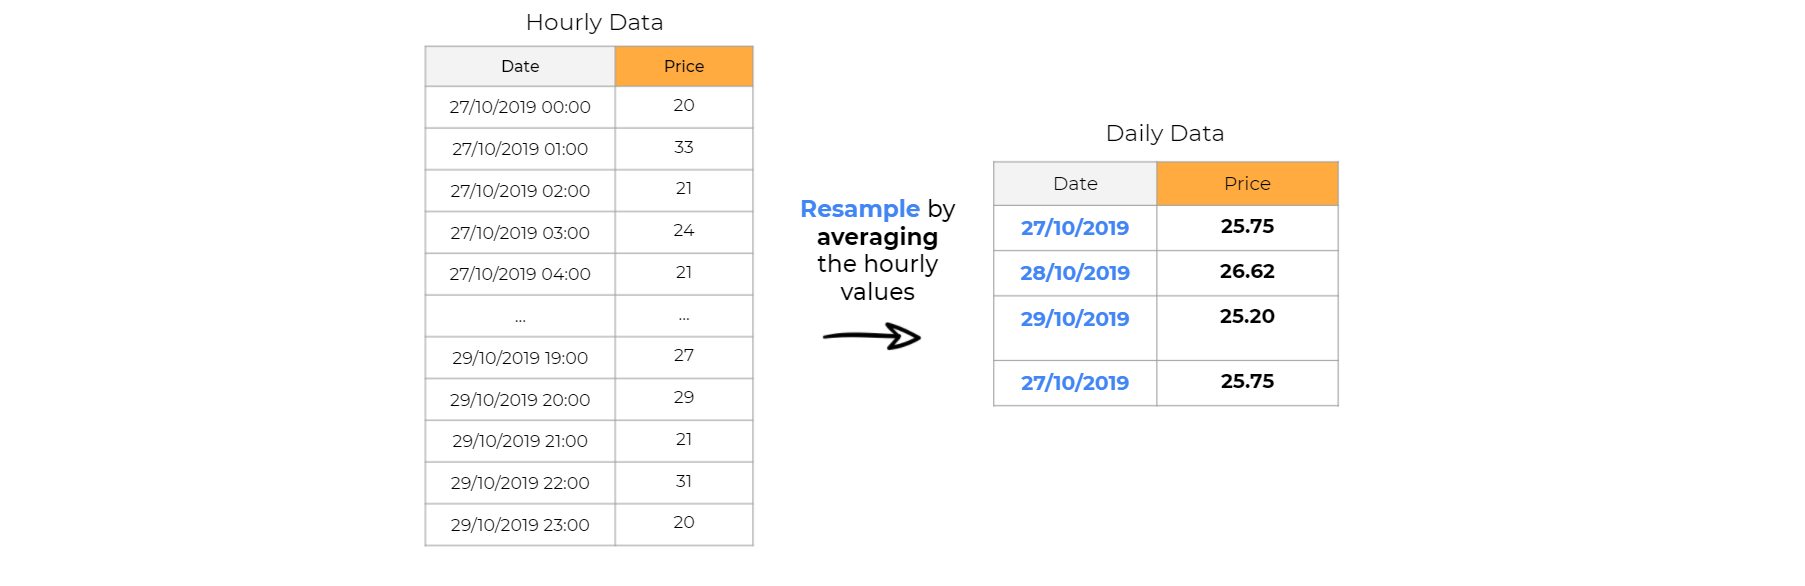

There could be a case where your time series data is in a base time that you are not interested in working with; for example, it is hourly based, and you are interested in changing to daily based.

- You can resample your time series, set this new time base and perform aggregation for the new time base, using .resample(). The documentation is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.resample.html).

Consider the following dataset made with NumPy random functions and an index made with pd.date_range()

In [242]:
np.random.seed(1)
df = pd.DataFrame(data={'Price':np.random.randint(low=20,high=35,size=72) }, 
                    index=pd.date_range(start='27/10/2019 00:00:00', periods=72,freq='H'))
df

C:\Users\zainab\AppData\Local\Temp\ipykernel_14380\3533075063.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  index=pd.date_range(start='27/10/2019 00:00:00', periods=72,freq='H'))


,Price
2019-10-27 00:00:00,25
2019-10-27 01:00:00,31
2019-10-27 02:00:00,32
2019-10-27 03:00:00,28
2019-10-27 04:00:00,29
...,...
2019-10-29 19:00:00,31
2019-10-29 20:00:00,32
2019-10-29 21:00:00,30
2019-10-29 22:00:00,24


Use .resample() to change your time series base time

- The 'rule' argument is the new frequency you are interested in. It follows the same convention we presented earlier; the documentation is found [here](https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases)
- Once you define the rule, you should set the aggregation function you wish to use. We selected .mean().
- In the end, the code below will get the content of DataFrame df, resample by day and calculate the mean for each day

In [243]:
df_resampled = df.resample(rule='D').mean()
df_resampled

,Price
2019-10-27,27.291667
2019-10-28,27.708333
2019-10-29,26.583333


**PRACTICE:** Consider historical sales data for 45 stores located in different regions - each store contains a number of departments. Let’s load the DataFrame, change ‘Date’ column type to “datetime64”, set ‘Date’ column as dataframe index, select rows for 1st department of the 1st Store and drop all other columns except ‘Weekly_Sales’. The code for such actions is shown below.

In the cell indicated below

- Use the resample method to display the DataFrame, setting the frequency for monthly and use the aggregation method sum().

In [244]:

df_sales = pd.read_csv("sales-data-set.csv")
df_sales['Date'] = pd.to_datetime(df_sales['Date'])

df_sales.index = df_sales['Date']

df_sales = df_sales[
    (df_sales['Store'] == 1) &
    (df_sales['Dept'] == 1)
]

df_sales = df_sales.drop(
    ["Store", "Dept", "Date", "IsHoliday"],
    axis=1
)

df_sales = df_sales.rename(columns={'Weekly_Sales': 'Sales'})

df_sales

,Sales
Date,
2010-05-02,24924.50
2010-05-03,21827.90
2010-05-14,18926.74
2010-05-21,14773.04
2010-05-28,15580.43
2010-06-08,17508.41
2010-05-11,34238.88


In [245]:
df_sales.columns

Index(['Sales'], dtype='object')

In [246]:
# Write your code here
df_resample = df_sales.resample(rule="M").sum() 

df_resample 

C:\Users\zainab\AppData\Local\Temp\ipykernel_14380\564405620.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_resample = df_sales.resample(rule="M").sum()


,Sales
Date,
2010-05-31,130271.49
2010-06-30,17508.41


#### Moving Average


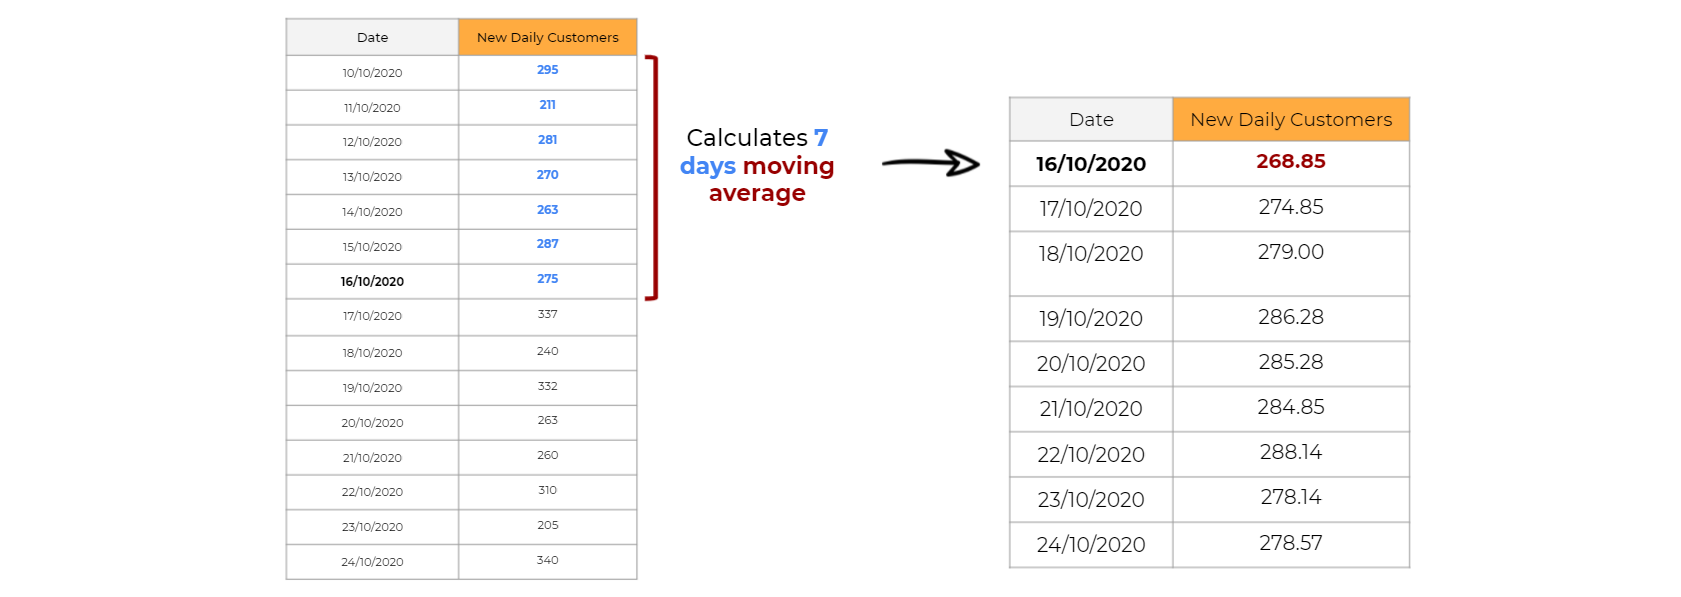

Pandas can handle moving averages also

- A moving average creates a series of averages of different subsets of the full data. You define a 'window' that defines the size of these subsets. This is useful to understand time-series trends, and if your data is changing too much too fast, the moving average gives you a better perception of how your data is behaving
  - Consider the DataFrame below, daily based with 15 periods, starting on 10 Oct 2020.

In this example, it shows the daily revenue for your fictitious local store

In [247]:
np.random.seed(101)
df = pd.DataFrame(data={'Revenue':np.random.randint(low=200,high=350,size=15) }, 
                    index=pd.date_range(start='10/10/2020', periods=15,freq='D'))
df

,Revenue
2020-10-10,295
2020-10-11,211
2020-10-12,281
2020-10-13,270
2020-10-14,263
2020-10-15,287
2020-10-16,275
2020-10-17,337
2020-10-18,240
2020-10-19,332


You will use .rolling(). The function documentation can be found [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html)

You want to calculate the moving average for four days (window=4) and get the mean across the windows.

- You will save the result in a variable called 'RevenueMovingAvg' just to better understand the operation
- The logic is the following: grab four consecutive days and calculate the average. Keep doing that for all days.
  - Look at the index 2020-10-24. The value of RevenueMovingAvg is the average of Revenue from 2020-10-21 to 2020-10-24.
  - The calculation of the mean is "moving" across the chunks of 4 days. That is why it's called the moving average.
  - You will notice the first three days don't have a moving average since they don't have enough "predecessor neighbours" to calculate a moving average.

In [248]:
df_example = df.copy()
df_example['RevenueMovingAvg'] = df_example['Revenue'].rolling(window=4).mean()
df_example

,Revenue,RevenueMovingAvg
2020-10-10,295,NaN
2020-10-11,211,NaN
2020-10-12,281,NaN
2020-10-13,270,264.25
2020-10-14,263,256.25
2020-10-15,287,275.25
2020-10-16,275,273.75
2020-10-17,337,290.50
2020-10-18,240,284.75
2020-10-19,332,296.00


**PRACTICE:** The DataFrame below is a copy of the df_sales Dataframe from previous practice..

In the cell indicated below

- Working directly on the Sales column, use the rolling method to calculate the sum moving across chunks of 12 months.

In [249]:
df_rolling = df_sales.copy()
df_rolling.head()

,Sales
Date,
2010-05-02,24924.50
2010-05-03,21827.90
2010-05-14,18926.74
2010-05-21,14773.04
2010-05-28,15580.43


In [250]:
# Write your code here
df_rolling['MovingSum'] = df_rolling['Sales'].rolling(window=2).sum() 

df_rolling 

,Sales,MovingSum
Date,,
2010-05-02,24924.50,NaN
2010-05-03,21827.90,46752.40
2010-05-14,18926.74,40754.64
2010-05-21,14773.04,33699.78
2010-05-28,15580.43,30353.47
2010-06-08,17508.41,33088.84
2010-05-11,34238.88,51747.29


#### Shift


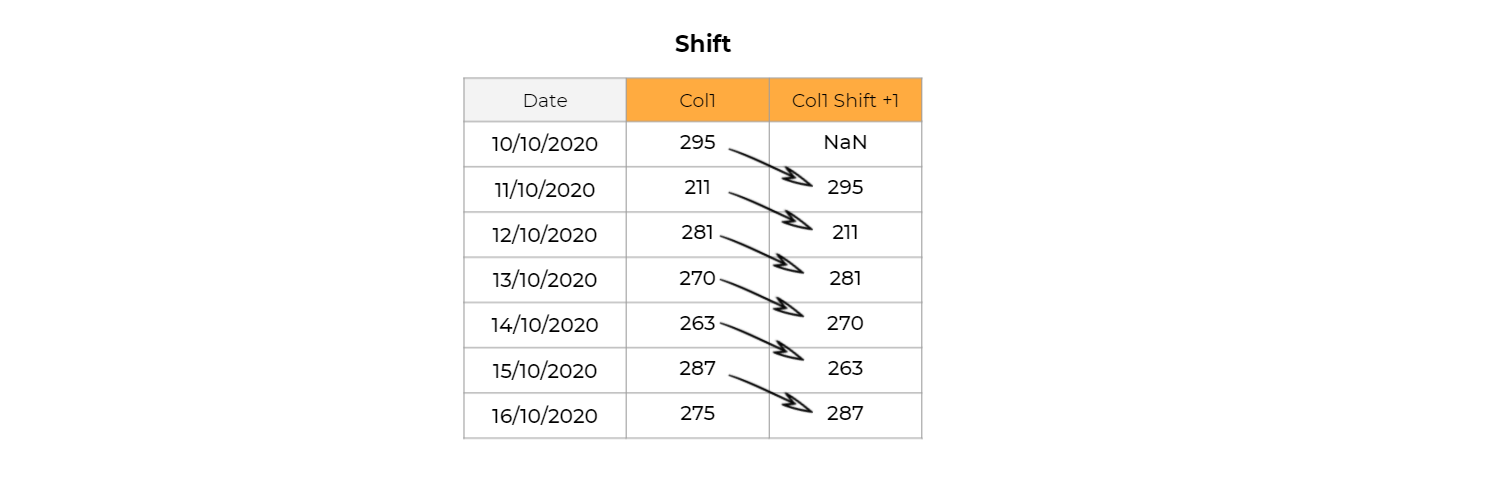

You can shift your data by the desired number of periods.

This operation typically makes sense in time series data; however, it can be applied in other circumstances
Use the method .shift() and define the number of periods to shift. The documentation is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.shift.html)
In this example, we selected periods as 1 and -1. So we are shifting forward one period in one column and shifting backwards one period in the other column. This argument is an integer and could be positive or negative

In [251]:
df_example = df.copy()
df_example['RevenueShift+1'] = df_example['Revenue'].shift(periods=1) 
df_example['Revenueshift-1'] = df_example['Revenue'].shift(periods=-1) 
df_example

,Revenue,RevenueShift+1,Revenueshift-1
2020-10-10,295,NaN,211.0
2020-10-11,211,295.0,281.0
2020-10-12,281,211.0,270.0
2020-10-13,270,281.0,263.0
2020-10-14,263,270.0,287.0
2020-10-15,287,263.0,275.0
2020-10-16,275,287.0,337.0
2020-10-17,337,275.0,240.0
2020-10-18,240,337.0,332.0
2020-10-19,332,240.0,263.0


#### Difference


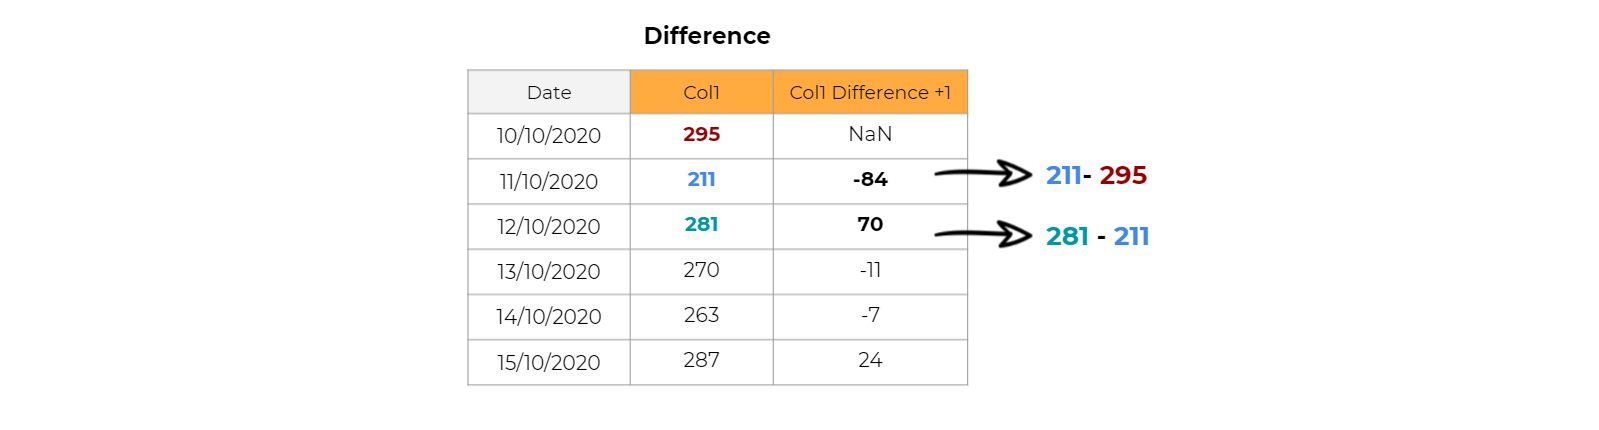

- Staying with the "local store revenue" example, you may be interested in calculating the difference between one row element and another. You can do that with .diff(). The link to the documentation is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.diff.html)
- This is useful for getting one aspect of how your time series data is changing. In this case, you want to know how much more or less money you are making compared to the previous day
The 'periods' argument is an integer and can be positive or negative
- When period=1, the first element will be NaN since there is no previous element to compare with

In [252]:
df_example = df.copy()
df_example['RevenueDiff1'] = df_example['Revenue'].diff(periods=1) 
df_example

,Revenue,RevenueDiff1
2020-10-10,295,NaN
2020-10-11,211,-84.0
2020-10-12,281,70.0
2020-10-13,270,-11.0
2020-10-14,263,-7.0
2020-10-15,287,24.0
2020-10-16,275,-12.0
2020-10-17,337,62.0
2020-10-18,240,-97.0
2020-10-19,332,92.0


#### Percentage Change


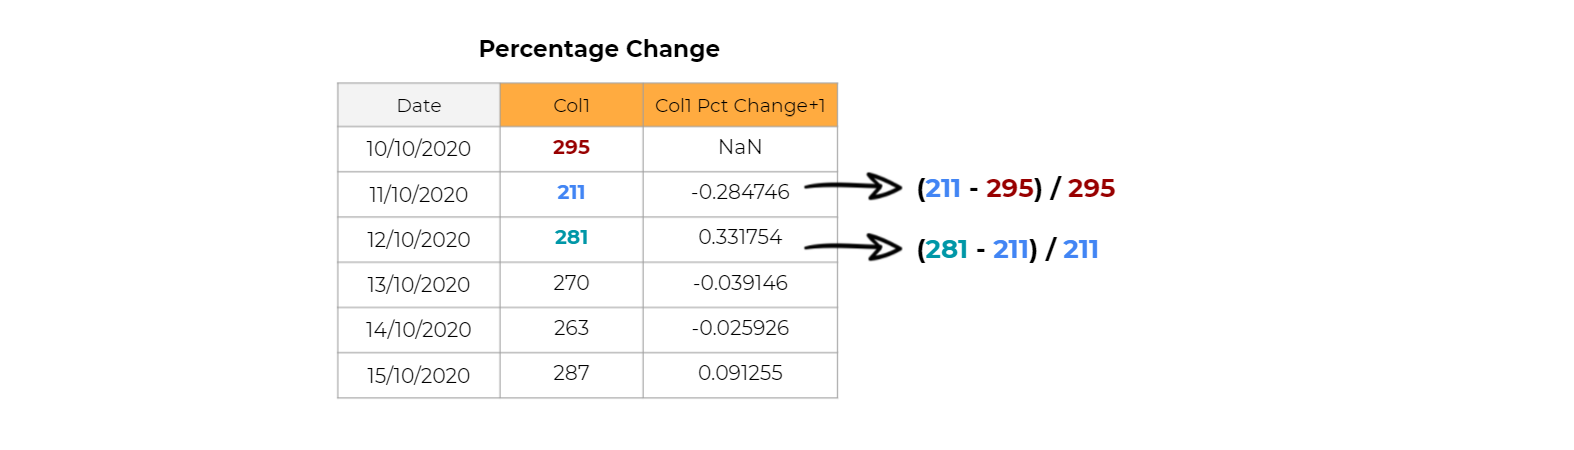

The previous example shows the absolute difference. You can get percentual change with .pct_change(). The link for documentation is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.pct_change.html)

- The use case here, when the period is 1, is to know the percentage increase/decrease of your revenue between days
  - When period=1, the first element will be NaN since there is no previous element to compare with

In [253]:
df_example = df.copy()
df_example['PctChange1'] = df_example['Revenue'].pct_change(periods=1) 
df_example

,Revenue,PctChange1
2020-10-10,295,NaN
2020-10-11,211,-0.284746
2020-10-12,281,0.331754
2020-10-13,270,-0.039146
2020-10-14,263,-0.025926
2020-10-15,287,0.091255
2020-10-16,275,-0.041812
2020-10-17,337,0.225455
2020-10-18,240,-0.287834
2020-10-19,332,0.383333
